# Different Theta Conditions: Clean Theta, No Theta, Scrambled Theta
Plots for the different theta conditions and degrees of scrambling and how they affect the LFP trace. 

## Quick Explanation of Theta Conditions

### *Clean Theta*
As mentioned above the global theta oscillation is given by 

$\Phi_\theta(t) = 2\pi v_\theta t$   $(mod 2\pi)$

where $v_\theta =$ frequency of theta, and $\Phi_\theta(t) ∈ [0, 2\pi]$.

This global theta oscillation resets after each cycle, meaning it is rhytmic and predictable and can be easily reconstructed retrospectively for each moment of time $t$, as long as the phase of theta at $t=0$ is known, which is the case in this model.
Theta modulation and phase precession occur in that the preferred phase moves to earlier and earlier phases of the cycle as the agent traverses the field, leading to a higher probability of spikes occurring in that window when the global osicllation phase at time $t$ matches the preferred phase at time $t$. 

### *No Theta*
In the "no theta" condition there is no modulation of the pure spatial rate code by a theta modulation factor. This means that the weights in the weight matrix are still learned via the STDP learning rule, but this learning rule uses the pure spatial rate code which is then simply
 
$f_j(x(t))=f_j^x(x)$

In conclusion, and to put it simply, the weights in the matrix are learned using the pure spatial rate code; no temporal modulation via theta takes place. 

### *Scrambled Theta*
In the scrambled theta condition there is no rhytmic and predictable global oscillation anymore, instead the global oscillation was generated as a circular Brownian motion (random walk on the unit (i.e $2\pi$) circle). This disrupts phase precession, while the pure spatial firing patterns, i.e. the spatial rate code, is preserved. This approach leads to phase diffusion rather than periodic oscillation with superimposed noise, matching the biophysical disruption observed in optogenetic frequency scrambling studies (e.g. Etter et al., 2023). The phase of the scrambled global oscillation evolves incrementally according to the following stochastic differential equation:

$$\phi_\theta^{scr}(t + \Delta t) = \left[ \phi_\theta^{scr}(t) + 2\pi \nu_\theta \Delta t + \xi(t) + \eta(t) \right] \mod 2\pi$$

where:
- $\nu_\theta = 10$ Hz (nominal theta frequency)
- $\Delta t = 1$ ms (simulation timestep)
- $\xi(t) \sim \mathcal{N}(0, \sigma_{scramble} = 0.5)$ radians (adds noise)
- $\eta(t) \sim \mathcal{N}(0, \sigma_{HF} = 0.5)$ radians (also adds noise)
- $\mod 2\pi$ constrains $\phi_\theta^{scr}(t) \in [0, 2\pi)$ to still allow for calculation of the modulated firing rate with the vonMises distribution which expects a phase on the unit circle

**Continuity with clean theta:** When noise is zero (i.e. $\sigma_{scramble} = \sigma_{HF} = 0$), the update rule of $\phi_\theta^{scr}(t + \Delta t)$ produces identical phase progression to clean theta, as only the drift term remains which decribes a clean 10Hz oscillation. Thsi means that the strength or amount of scrambling can be controlled via the two parameters $\xi(t)=scramblingStrength$ (low frequency noise) and $\eta(t)=hfStrength$ (high frequency noise).  

In [ ]:
# Imports
import sys # for path management
sys.path.insert(0, "/Users/liviastein/STDP_Theta-1/STDP-SR_scripts/Task_Setup/MazeAgent_Scripts")  # Ensure current directory is in path
from MazeAgent_HA import *  # import all functions from MazeAgent_Script
import copy
import tomplotlib.tomplotlib as tpl
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

%load_ext autoreload
%autoreload 1

#for plotting in notebook
%matplotlib inline  

### Define Parameters, agent, visualiser

Setting parameters
Initialising
   making state/history dataframes
   initialising velocity, position and direction
   setting time/run counters
   initialising theta phases: clean and scrambled
   making the maze walls
   discretising position for later plotting
   handling undefined parameters
   initialising basis features for learning
   calculating state vector at all discretised positions


  0%|          | 0/10000 [00:00<?, ?it/s]

   initialising STDP weight matrix and traces
Adding 'theta scrambled' Condition
DONE


(<Figure size 4000x160 with 1 Axes>, <Axes: >)

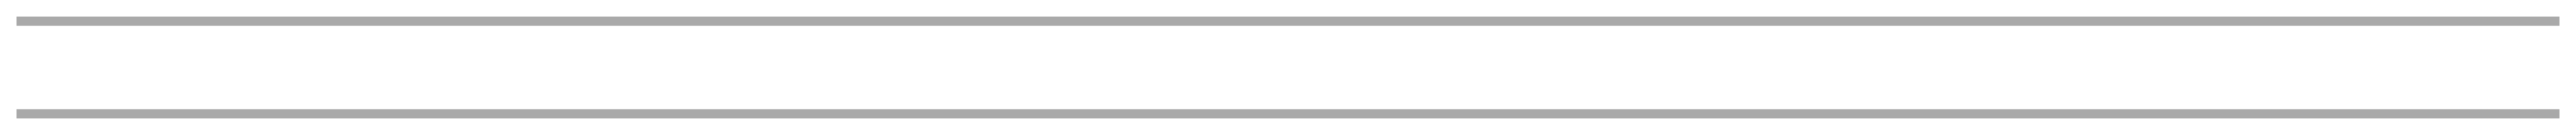

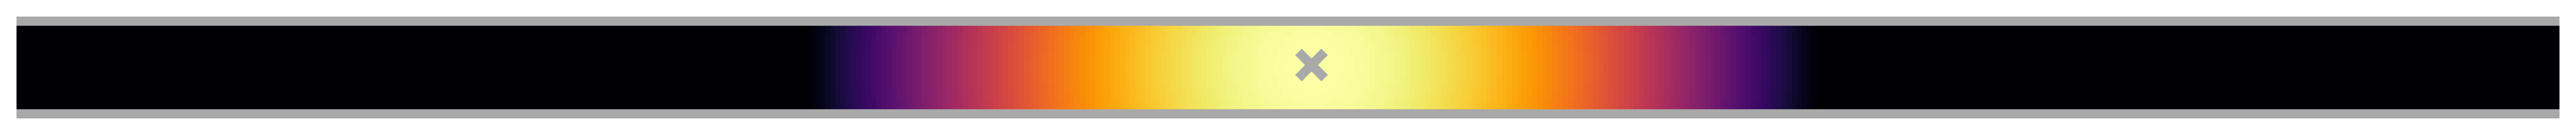

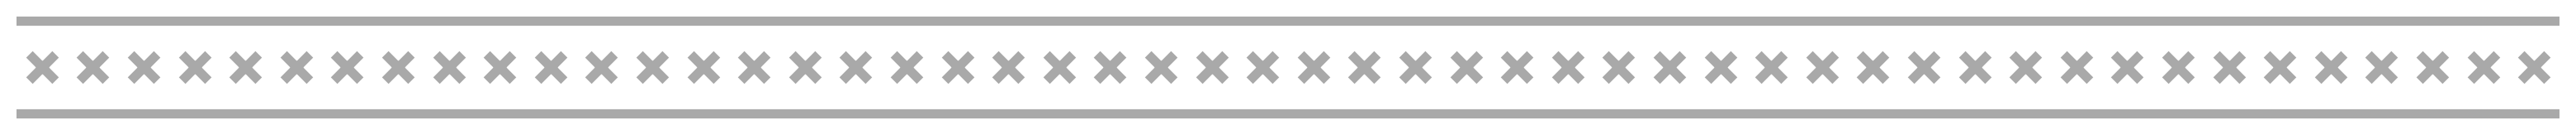

In [22]:
## Define parameters for maze and agent
# number of placeCells
N=50

# set x and y coordinates for place cell centres
xcen = np.linspace(0,5,N+1)[:-1] # we want to place N place cells evenly across the 5m length of the maze, so we create N+1 evenly spaced points and then take all but the last one (which is at 5m) to get the centres of the place cells.
xcen += (xcen[1] - xcen[0]) / 2 # we want the first place cell to be centred at 0.1m, so we shift all the centres by half the distance between them (i.e. the distance between the first centre and 0m) to get the final x coordinates of the place cell centres.
ycen = np.array([0.1]*N) # we want all the place cells to be centred at 0.1m in the y direction (i.e. 10cm from the south wall) so we set all the y coordinates of the place cell centres to 0.1m.
centres = np.vstack((xcen,ycen)).T # we combine the x and y coordinates into a single array of shape (N,2) where each row is the (x,y) coordinates of a place cell centre.

# set parameters for the MazeAgent class
params = {
           #Maze params 
          'mazeType'            : 'loop',  #type of maze, define in getMaze() function
          'stateType'           : 'gaussianThreshold', #feature on which to TD learn (onehot, gaussian, gaussianCS, circles, bump)
          'movementPolicy'      : 'windowsScreensaver',  #movement policy (raudies, random walk, windows screensaver)
          'roomSize'            : 5,          #maze size scaling parameter, metres
          'dt'                  : 0.005,       #simulation time disretisation (defualts to largest )
          'dx'                  : 0.01,       #space discretisation (for plotting, movement is continuous)
          'speedScale'          : 0.16,       #movement speed scale, metres/second
          'rotSpeedScale'       : None,       #rotational speed scale, radians/second
          'initPos'             : None,  #initial position [x0, y0], metres
          'initDir'             : None,      #initial direction, unit vector
          'nCells'              : N,       #how many features to use
          'centres'             : centres,       #array of receptive field positions. Overwrites nCells
          'sigma'               : 1,          #basis cell width scale (irrelevant for onehots)
          'doorsClosed'         : False,       #whether doors are opened or closed in multicompartment maze
          'reorderCells'        : True,       #whether to reorde the cell centres which have been provided
          'firingRateLookUp'    : False,      #use quantised lookup table for firing rates 
          'biasDoorCross'       : False,      #if True, in twoRoom maze door crossings are biased towards
          'biasWallFollow'      : True,       #if True, agent aligns to wall when gets too near.

          #TD params 
          'tau'                 : 4,          #TD decay time, seconds
          'TDdx'                : 0.1,       #rough distance between TD learning updates, metres 
          'alpha'               : 0.01,       #TD learning rate 
          'successorFeatureNorm': 100,        #linear scaling on successor feature definition found to improve learning stability
          'TDreg'               : 0.01,       #L2 regularisation 
          
          #STDP params
          'peakFiringRate'      : 5,          #peak firing rate of a cell (middle of place field,preferred theta phase)
          'tau_STDP_plus'       : 20e-3,      #pre trace decay time
          'tau_STDP_minus'      : 40e-3,      #post trace decay time
          'a_STDP'              : -0.4,       #pre-before-post potentiation factor (post-before-pre = 1) 
          'eta'                 : 0.01,       #STDP learning rate
          'baselineFiringRate'  : 0,          #baseline firing rate for cells 
          'use_full_STDP_rule'  : True,      #whether to use full STDP rule     
          'online_mapping'      : 'identity',  #how to map CA3-->CA1 during learning
          'rownorm'             : False,

          #Theta precession params
          'thetaFreq'           : 10,         #theta frequency
          'precessFraction'     : 0.5,        #fraction of 2pi the prefered phase moves through
          'kappa'               : 1,          # von mises spread parameter
          
          #Theta scrambling params (Livi addition)
          'scramble_strength'    : 0.0,        # strength of theta phase scrambling 
          'hf_strength'          : 0.0,        # strength of high frequency jitter added to scrambled theta phase

}

agent_scr = MazeAgent(params)
plotter = Visualiser(agent_scr)
agent_scr.toggleDoors(params['doorsClosed'])

plotter.plotMazeStructure() # plot maze structure to check it's correct before starting simulation
plotter.plotReceptiveField(25) # plot receptive field of place cell 25 in the middel of loop
plotter.plotFeatureCells(centresOnly=True, textlabel=False) # plots centres of the place cells in maze (no heatmap)


### Simulation Loop

  0%|          | 0/360000 [00:00<?, ?it/s]

Calculating place and grid cells


(<Figure size 400x400 with 2 Axes>,
 <Axes: title={'center': "TD matrix 'M' after 30min of TD learning"}>,
 <Axes: >)

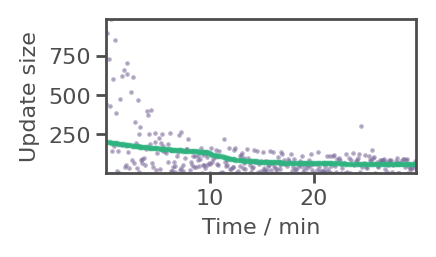

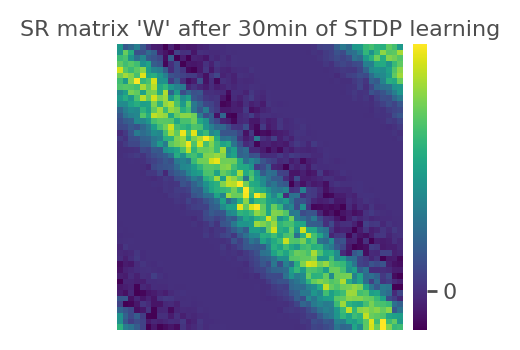

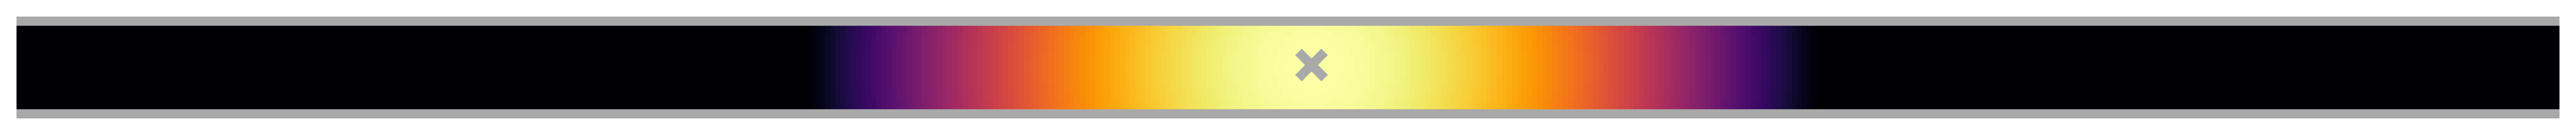

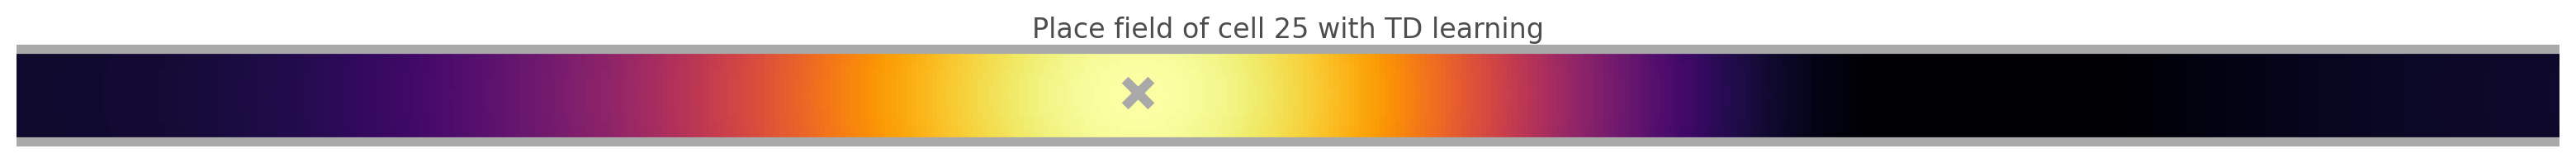

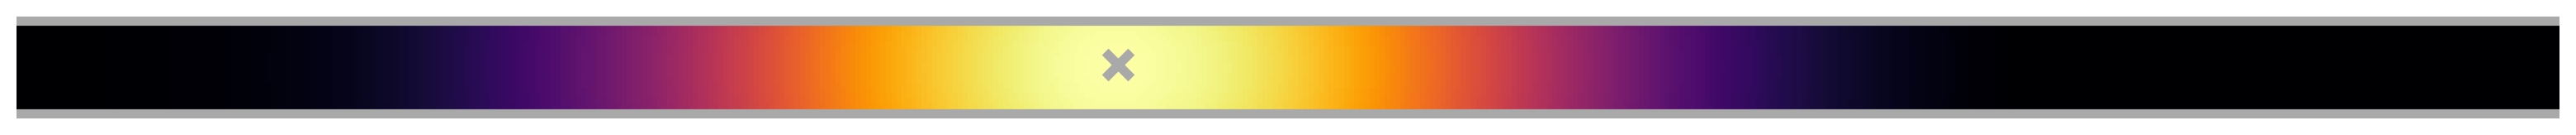

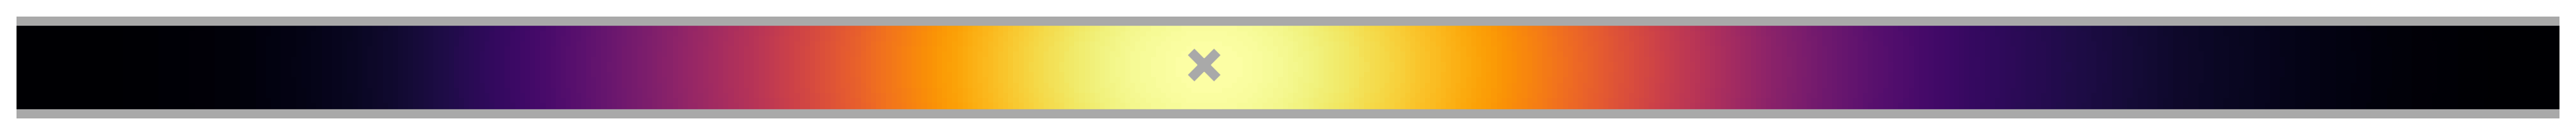

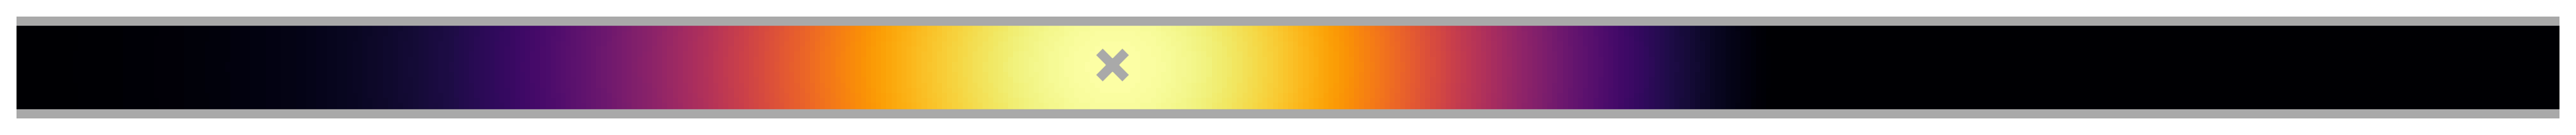

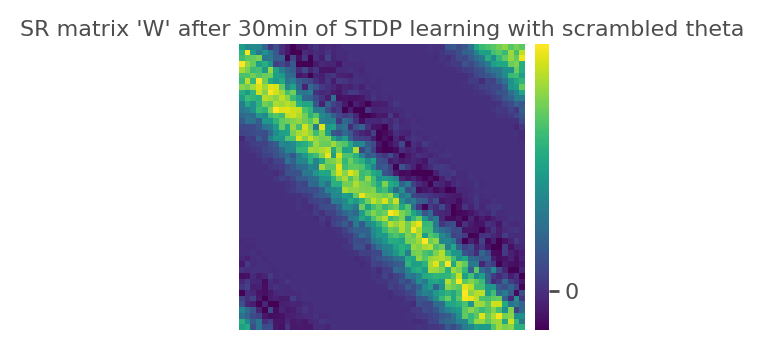

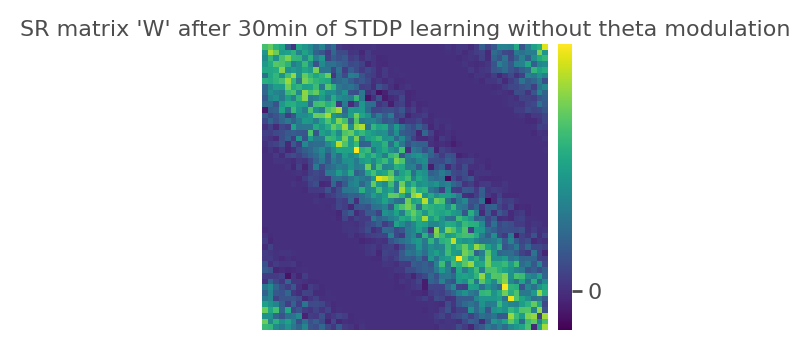

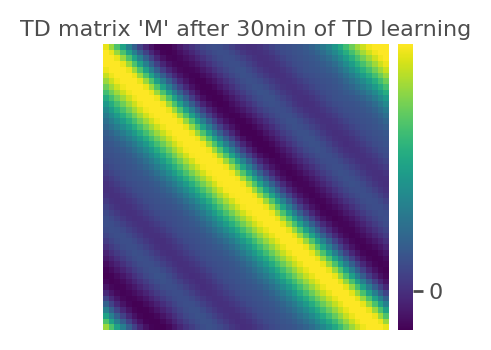

In [ ]:
# Set parameters and run simulation
agent_scr.pos = np.array([0,0.1])  
agent_scr.dir = np.array([1,0]) # start at the west end of the loop, facing east, so we can follow the walls in a clockwise direction

# Define agent to train for 30min (as in paper), with STDP learning, no TD learning and save snapshots every 1min
model1= agent_scr.runRat(trainTime=30, STDPLearn=True, TDSRLearn=True, saveEvery=0.5)
model1

# Define what to plot from this STDP run
plotter = Visualiser(agent_scr) # create new plotter to access the data from the STDP run we just did

# PLOTTING
# plot STDP weight matrix 'W' with clean theta
#lotter.plotM(whichM="W", colorbar=True, title="SR matrix 'W' after 30min of STDP learning", save=True)
# plot basis feature again
#plotter.plotReceptiveField(25)

# plot place field of cell 25 with TD learning 
#fig, ax=plotter.plotPlaceField(hist_id=-1, number=25, save=True, STDP=False, threshold=0.0)
#ax.set_title("Place field of cell 25 with TD learning", fontsize=12)

# plot place field of cell 25 with STDP learning (clean theta)
#plotter.plotPlaceField(hist_id=-1, number=25, save=True, STDP=True, no_theta=False, threshold=0.0)

# plot place field of cell 25 with STDP learning but no theta modulation 
#plotter.plotPlaceField(hist_id=-1, number=25, save=True, STDP=True, no_theta=True, threshold=0.0)

# scrambled that place field of cell 25 with STDP learning but no theta modulation
#plotter.plotPlaceField(hist_id=-1, number=25, save=True, STDP=True, no_theta=False, scrambled=True, threshold=0.0)

# Plot scrambled
#plotter.plotM(whichM="W_scrambled", colorbar=True, title="SR matrix 'W' after 30min of STDP learning with scrambled theta", save=True) 

# Plot no_theta
#plotter.plotM(whichM="W_notheta", colorbar=True, title="SR matrix 'W' after 30min of STDP learning without theta modulation", save=True)

# Plot TD plots
#plotter.plotM(whichM="M", colorbar=True, title="TD matrix 'M' after 30min of TD learning", save=True)


# Plot combined plots 
#plotter.plotMAveraged(time=None, x_ticks=None, plot_no_theta=True, color='C7',ylim=None, renorm=True, return_data=True)
#plotter.plotMetrics(total_time=None, x_ticks=None)

### Scrambled plot for differnet theta conditions in one plot

In [103]:

# Generate scrambled theta data for different scrambling strengths
def generate_scrambled_theta(duration_min=10.0, scramble_strength=0.5, hf_strength=0.5, 
                            dt=0.005, theta_freq=10.0):
    """
    Generate scrambled theta phase data without needing an agent.
    
    Parameters:
    - duration_min: duration in minutes
    - scramble_strength: low-frequency noise SD (radians)
    - hf_strength: high-frequency jitter SD (radians)
    - dt: timestep (seconds)
    - theta_freq: theta frequency (Hz)
    
    Returns:
    - times: time history
    - phases: phase history
    """
    steps = int((duration_min * 60.0) / dt)
    times = np.arange(steps) * dt
    phases = []
    
    theta_phase = 0.0
    drift = theta_freq * dt * 2 * np.pi
    
    for i in range(steps):
        scramble_noise = np.random.normal(0, scramble_strength)
        hf_jitter = np.random.normal(0, hf_strength)
        theta_phase = (theta_phase + drift + scramble_noise + hf_jitter) % (2 * np.pi)
        phases.append(theta_phase)
    
    return times, np.array(phases)

# Generate data for all scrambling strengths
scramble_strengths = [0.1, 0.2, 0.3, 0.4, 0.5]
theta_data = {}

for strength in scramble_strengths:
    times, phases = generate_scrambled_theta(
        duration_min=10.0, 
        scramble_strength=strength, 
        hf_strength=strength,  # match hf_strength to scramble_strength
        dt=agent_scr.dt, 
        theta_freq=agent_scr.thetaFreq
    )
    theta_data[strength] = {'times': times, 'phases': phases}
    print(f"Generated theta data for scramble_strength={strength}")

print("\nStored in theta_data dict with keys:", list(theta_data.keys()))
print("Each entry has 'times' and 'phases' arrays")


Failed to reload module 'traitlets.utils.bunch' from file '/Users/liviastein/STDP_Theta-1/.venv/lib/python3.12/site-packages/traitlets/utils/bunch.py'
Traceback (most recent call last):
  File "/Users/liviastein/STDP_Theta-1/.venv/lib/python3.12/site-packages/IPython/extensions/autoreload.py", line 325, in check
  File "/Users/liviastein/STDP_Theta-1/.venv/lib/python3.12/site-packages/IPython/extensions/autoreload.py", line 625, in superreload
  File "/Users/liviastein/STDP_Theta-1/.venv/lib/python3.12/site-packages/IPython/extensions/autoreload.py", line 451, in update_generic
    old_objects = {}
        ^^^^^^^^^^^^
  File "/Users/liviastein/STDP_Theta-1/.venv/lib/python3.12/site-packages/IPython/extensions/autoreload.py", line 403, in update_class
    def __init__(self, obj):
           ^^^^^^^^^^^^^^^^^^
  File "/Users/liviastein/STDP_Theta-1/.venv/lib/python3.12/site-packages/IPython/extensions/autoreload.py", line 451, in update_generic
    old_objects = {}
        ^^^^^^^^^^^^


Unexpected exception formatting exception. Falling back to standard exception

Failed to reload module 'IPython.utils.syspathcontext' from file '/Users/liviastein/STDP_Theta-1/.venv/lib/python3.12/site-packages/IPython/utils/syspathcontext.py'
Traceback (most recent call last):
  File "/Users/liviastein/STDP_Theta-1/.venv/lib/python3.12/site-packages/IPython/extensions/autoreload.py", line 325, in check
  File "/Users/liviastein/STDP_Theta-1/.venv/lib/python3.12/site-packages/IPython/extensions/autoreload.py", line 625, in superreload
  File "/Users/liviastein/STDP_Theta-1/.venv/lib/python3.12/site-packages/IPython/extensions/autoreload.py", line 451, in update_generic
    old_objects = {}
        ^^^^^^^^^^^^
  File "/Users/liviastein/STDP_Theta-1/.venv/lib/python3.12/site-packages/IPython/extensions/autoreload.py", line 419, in update_class
    ]
      
  File "/Users/liviastein/STDP_Theta-1/.venv/lib/python3.12/site-packages/IPython/extensions/autoreload.py", line 373, in update_instances
KeyboardInterrupt
--- Logging error ---


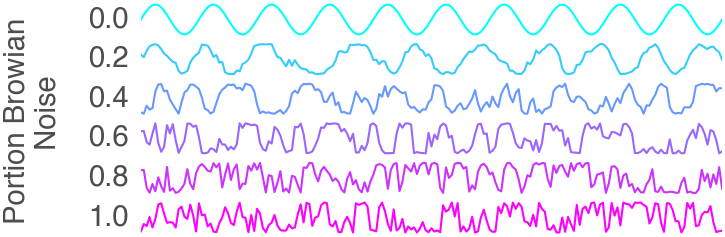

In [95]:
# Plot clean theta and scrambled variants with a colour gradient reflecting scramble strength
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
plt.style.use('/Users/liviastein/STDP_Theta-1/ResultPipelines/plot_style.mplstyle')


# reference times (assumes theta_data was generated with same time base)
ref_times = theta_data[0.2]['times']
mask = ref_times <= 1.0  # plot first 1 second for clarity

scramble_strengths = [0.2, 0.4, 0.6, 0.8, 1.0]
conditions = [0.0] + scramble_strengths  # 0.0 denotes the intact/clean condition
n = len(conditions)

fig, axes = plt.subplots(n, 1, figsize=(2.5, 1))
axes = np.atleast_1d(axes)

cmap = plt.get_cmap('cool')
norm = mpl.colors.Normalize(vmin=0.0, vmax=1.0)

# Remove top/right spines for all axes
for a in axes:
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)

for i, strength in enumerate(conditions):
    color = cmap(i / (n - 1)) if n > 1 else cmap(0)
    ax = axes[i]
    if strength == 0.0:
        phases = np.mod(2 * np.pi * agent_scr.thetaFreq * ref_times, 2 * np.pi)
        label = 'Clean (0.0)'
    else:
        phases = theta_data[strength]['phases']
        label = f'Scramble={strength}'

    ax.plot(ref_times[mask], np.sin(phases[mask]), color=color, label=label)
    ax.set_ylim(-1.1, 1.1)
    #a.tick_params(axis='y', labelleft=False)
    #ax.grid(True, alpha=0.9)
    ax.set_ylabel(f'{strength}')
    # remove y axes of all plots
    #ax.set_yticks([])
    #ax.legend(loc='upper right', fontsize=9)

# Hide x-axis ticks/labels and bottom spine for all except bottom
for a in axes:
    #a.tick_params(labelbottom=False, which='major', bottom=False, left= False, labelleft=False)
    a.axes.set_axis_off()
    #a.tick_params(axis='y', labelleft=False)
    # add label to left of each plot with the scramble strength
    a.text(-0.02, 0.5, f'{a.get_ylabel()}', transform=a.transAxes, va='center', ha='right')
    a.spines['bottom'].set_visible(True)
    # add x axis only for bottom plot

# add y axis label to the left of the individual y axis labels
fig.text(-0.02, 0.5, 'Portion Browian \n Noise', va='center', ha='center', rotation='vertical', fontweight='bold', fontfamily= 'helvetica')
# Only bottom axis shows x-axis
axes[-1].set_xlabel('Time (s)')

# Make room for a right-side vertical colorbar and ensure it spans the axes height
#fig.subplots_adjust(right=0.88)
#sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
#sm.set_array([])
#cb = fig.colorbar(sm, ax=axes.tolist(), orientation='vertical', fraction=0.035, pad=0.04)
#cb.set_ticks(conditions)
#cb.ax.tick_params()
#cb.set_label('Scramble Strength')
#cb.ax.invert_yaxis()

# save figure
#plt.savefig("/Users/liviastein/STDP_Theta-1/Final_Figures/ScrambleConditions.pdf", transparent=True)

#plt.tight_layout()
plt.show()

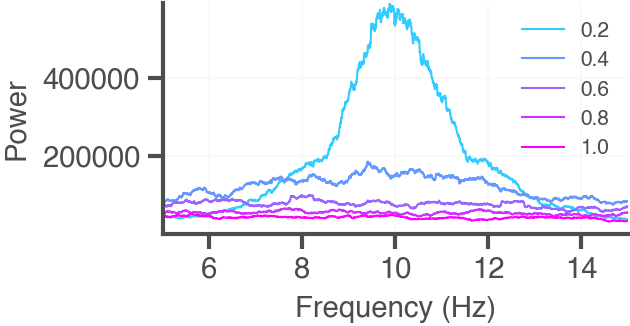

Scramble Strength | Min Power | Max Power
0.2 | 375.4881768028977 | 592766.0554273755
0.4 | 1512.3142196564684 | 185159.0910555524
0.6 | 3228.134717415664 | 99848.80677699608
0.8 | 5932.158864712288 | 72571.2334509274
1.0 | 8887.345056720225 | 54227.58822950443


In [67]:
# FFT plot for all conditions
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from scipy.fft import rfft, rfftfreq
from scipy.ndimage import uniform_filter1d

plt.style.use('/Users/liviastein/STDP_Theta-1/ResultPipelines/plot_style.mplstyle')

# Conditions and colormap
scramble_strengths = [0.2, 0.4, 0.6, 0.8, 1.0]  # include clean condition as 0.0
cmap = plt.get_cmap('cool')
norm = mpl.colors.Normalize(vmin=0.0, vmax=1.0)

# Use the generated 10 min traces; use the shared reference time base from the 0.2 condition
ref_times = theta_data[0.2]['times']
dt = float(ref_times[1] - ref_times[0])

def _condition_phase(strength):
    if strength == 0.0:
        return np.mod(2 * np.pi * agent_scr.thetaFreq * ref_times, 2 * np.pi)
    return np.asarray(theta_data[strength]['phases'], dtype=float)


def _fft_from_phase(phases, dt, smooth_hz=0.5):
    lfp = np.sin(np.asarray(phases, dtype=float))
    lfp = lfp - np.mean(lfp)
    window = np.hanning(len(lfp))
    windowed = lfp * window
    spectrum = np.abs(rfft(windowed)) ** 2
    freqs = rfftfreq(len(windowed), d=dt)

    # Smooth over a window corresponding to ~smooth_hz bandwidth
    freq_res = freqs[1] - freqs[0]          # Hz per bin
    n_bins = max(1, int(smooth_hz / freq_res))
    spectrum = uniform_filter1d(spectrum, size=n_bins)

    #if spectrum.max() > 0:
        #spectrum = spectrum / spectrum.max()
    return freqs, spectrum

fig, ax = plt.subplots(figsize=(2,1))

# plot spectrum as line plot for each condition, with colour reflecting scramble strength

for strength in scramble_strengths:
    phases = _condition_phase(strength)
    freqs, spectrum = _fft_from_phase(phases, dt)
    color = cmap(norm(strength))
    label = '0.0' if strength == 0.0 else f'{strength}'
    ax.plot(freqs, spectrum, color=color, label=label, linestyle='solid', drawstyle='default')

ax.set_xlim(5, 15)
#ax.set_ylim(1e-4, 6e1) # limity in line with log scale and observed spectra
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('Power')
#ax.set_yscale('log')
#ax.set_yscale('log')
ax.tick_params()
#ax.set_title('FFT of clean and scrambled theta conditions', fontweight='bold')
ax.grid(True, alpha=0.25)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(loc='upper right', frameon=False, fontsize=5)
#plt.semilogy(freqs, spectrum)

#sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
#sm.set_array([])
#cb = fig.colorbar(sm, ax=ax, orientation='vertical', fraction=0.035, pad=0.03)
#cb.set_ticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
#cb.ax.tick_params()
#cb.set_label('Scramble Strength')
#cb.ax.invert_yaxis()

# save figure
#plt.savefig("/Users/liviastein/STDP_Theta-1/Final_Figures/ScrambleConditions_FFT.png", transparent=True)
#plt.tight_layout()
plt.show()
# print minimum and maximum power in the spectra for each condition
print("Scramble Strength | Min Power | Max Power")
for strength in scramble_strengths:
    phases = _condition_phase(strength)
    freqs, spectrum = _fft_from_phase(phases, dt)
    print(f"{strength} | {spectrum.min()} | {spectrum.max()}")

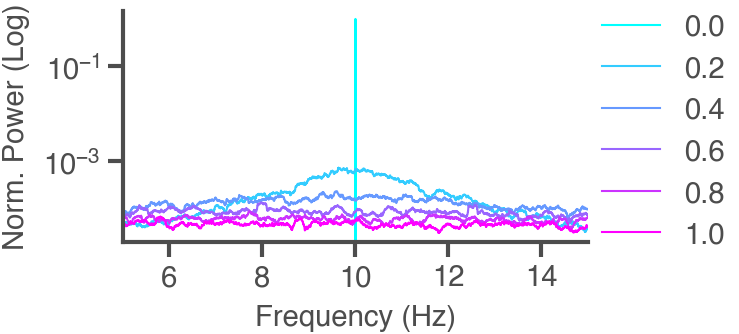

Scramble Strength | Min Power | Max Power
0.0 | 3.6981e-33 | 1.0000e+00
0.2 | 3.7153e-07 | 7.2408e-04
0.4 | 1.4454e-06 | 2.3121e-04
0.6 | 3.2577e-06 | 1.3302e-04
0.8 | 5.7626e-06 | 8.8314e-05
1.0 | 8.7742e-06 | 6.7829e-05


In [102]:
# FFT plot for all conditions
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from scipy.fft import rfft, rfftfreq
from scipy.ndimage import uniform_filter1d
plt.style.use('/Users/liviastein/STDP_Theta-1/ResultPipelines/plot_style.mplstyle')

# Conditions and colormap
scramble_strengths = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]  
cmap = plt.get_cmap('cool')
norm = mpl.colors.Normalize(vmin=0.0, vmax=1.0)

# Use the generated 10 min traces; use the shared reference time base from the 0.2 condition
ref_times = theta_data[0.2]['times']
dt = float(ref_times[1] - ref_times[0])

def _condition_phase(strength):
    if strength == 0.0:
        return np.mod(2 * np.pi * agent_scr.thetaFreq * ref_times, 2 * np.pi)
    return np.asarray(theta_data[strength]['phases'], dtype=float)

def _fft_from_phase(phases, dt, smooth_hz=0.5, smooth=True):
    lfp = np.sin(np.asarray(phases, dtype=float))
    lfp = lfp - np.mean(lfp)
    window = np.hanning(len(lfp))
    windowed = lfp * window
    spectrum = np.abs(rfft(windowed)) ** 2
    freqs = rfftfreq(len(windowed), d=dt)
    if smooth == True:
        freq_res = freqs[1] - freqs[0]
        n_bins = max(1, int(smooth_hz / freq_res))
        spectrum = uniform_filter1d(spectrum, size=n_bins)

    # NO normalization here — returns raw power
    return freqs, spectrum

# First pass: compute all spectra
spectra = {}
for strength in scramble_strengths:
    phases = _condition_phase(strength)
    freqs, spectrum = _fft_from_phase(phases, dt, smooth_hz=0.2, smooth=(strength != 0.0))  # smooth only scrambled conditions
    spectra[strength] = (freqs, spectrum)

# Normalize all to clean theta's peak
clean_peak = spectra[0.0][1].max()
for strength in scramble_strengths:
    freqs, spectrum = spectra[strength]
    spectra[strength] = (freqs, spectrum / clean_peak)

fig, ax = plt.subplots(figsize=(2, 1))

# Plot spectrum as line plot for each condition
for strength in scramble_strengths:
    freqs, spectrum = spectra[strength]
    color = cmap(norm(strength))
    label = '0.0' if strength == 0.0 else f'{strength}'
    ax.plot(freqs, spectrum, color=color, label=label, linestyle='solid')

ax.set_xlim(5, 15)
ax.set_yscale('log')
ax.set_ylim(0.00002, 1.5)  # cuts numerical noise, keeps meaningful signal
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('Norm. Power (Log)')
#ax.grid(True, alpha=0.25)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(loc='upper right', frameon=False, bbox_to_anchor=(1.35, 1.1))

# save figure
plt.savefig("/Users/liviastein/STDP_Theta-1/Final_Figures/ScrambleConditions_FFT.pdf", transparent=True)

#plt.tight_layout()
plt.show()

# Print min and max power for each condition
print("Scramble Strength | Min Power | Max Power")
for strength in scramble_strengths:
    freqs, spectrum = spectra[strength]
    print(f"{strength} | {spectrum.min():.4e} | {spectrum.max():.4e}")